# Taller 6 · Punto 1: generación de texto con «María» de Jorge Isaacs

**Procesamiento de Lenguaje Natural · Maestría · Camilo García**

Código: <https://github.com/CamiloGarcia06/maestria-pln/tree/taller-6>
Reporte escrito: [`README.md`](README.md)

**Objetivo.** Usar el colab del curso (*Deep Learning with Python*, 3.ª ed., «Training a Shakespeare language
model») para entrenar un **modelo de lenguaje por caracteres** con un libro que leyó el grupo: *María*
(Jorge Isaacs, 1867), y generar texto nuevo «al estilo» de la novela.

Respecto al colab cambiamos tres cosas, y cada una se mide:
1. **Validación**: el colab entrena sobre todo el texto y no sabe si el modelo sobreajusta. Aquí el último 10 % de
   la novela queda aparte y mide la pérdida (y la perplejidad) en texto que el modelo no vio.
2. **Ventanas solapadas y regularización**: el libro tiene menos de la mitad de caracteres que el Shakespeare del colab, así que
   comparamos el modelo tal cual con variantes que aprovechan mejor el texto.
3. **Muestreo con temperatura**: el colab genera con `argmax` (*greedy*), que se repite en bucles. Medimos cómo
   cambian la calidad y la diversidad del texto según la temperatura.

## 1. Configuración

Usamos el backend **TensorFlow** de Keras (el colab usaba JAX y necesitaba desactivar la pre-reserva de memoria);
el modelo y el código son los mismos.

In [2]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json, re, time
import warnings
# Avisos de Keras que no afectan el resultado: el tf.data ya viene barajado, y las subcapas internas de la
# atención de keras_hub no "usan" la máscara de relleno (la atención sí la recibe y la aplica).
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
warnings.filterwarnings("ignore", message=".*does not support masking.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEMILLA = 42
RUTA_LIBRO = Path("datos/maria.txt")          # se genera con scripts/descargar_maria.py
RESULTADOS = Path("resultados"); RESULTADOS.mkdir(exist_ok=True)
FIGURAS = Path("figuras"); FIGURAS.mkdir(exist_ok=True)
MODELOS = Path("modelos"); MODELOS.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEMILLA)
print("Keras", keras.__version__, "| backend", keras.backend.backend(), "| GPU:", tf.config.list_physical_devices("GPU"))

Keras 3.15.1 | backend tensorflow | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. El libro

*María* es de dominio público; el texto viene de [es.wikisource](https://es.wikisource.org/wiki/Mar%C3%ADa_(Isaacs))
(65 capítulos). El script `scripts/descargar_maria.py` lo baja capítulo por capítulo y lo deja en `datos/maria.txt`.

In [3]:
texto = RUTA_LIBRO.read_text(encoding="utf-8")
palabras = re.findall(r"\w+", texto.lower())
print(f"Caracteres: {len(texto):,} | palabras: {len(palabras):,} | palabras distintas: {len(set(palabras)):,}")
print(f"Caracteres distintos: {len(set(texto))}")
print(texto[:400])

Caracteres: 499,065 | palabras: 88,318 | palabras distintas: 11,947
Caracteres distintos: 88
Capítulo I

Era yo niño aún cuando me alejaron de la casa paterna para que diera principio a mis estudios en el colegio del doctor Lorenzo María Lleras, establecido en Bogotá hacía pocos años, y famoso en toda la República por aquel tiempo.
En la noche víspera de mi viaje, después de la velada, entró a mi cuarto una de mis hermanas, y sin decirme una sola palabra cariñosa, porque los sollozos le e


**División entrenamiento / validación.** Cortamos el libro en un salto de línea cerca del 90 %: los primeros ~58
capítulos son entrenamiento y el final de la novela es validación. Es un corte por posición (no aleatorio) para que
ninguna ventana de validación se solape con una de entrenamiento.

In [4]:
corte = texto.index("\n", int(0.9 * len(texto)))
texto_train, texto_val = texto[:corte], texto[corte:]
print(f"Entrenamiento: {len(texto_train):,} caracteres | validación: {len(texto_val):,}")

Entrenamiento: 449,566 caracteres | validación: 49,499


## 3. Tokenización por caracteres

Igual que en el colab: `TextVectorization(split="character", standardize=None)` conserva mayúsculas, tildes y
puntuación, porque el modelo debe aprender a escribirlas. El vocabulario se ajusta solo con entrenamiento.

In [5]:
tokenizador = layers.TextVectorization(standardize=None, split="character")
tokenizador.adapt([texto_train])
vocabulario = tokenizador.get_vocabulary()
TAM_VOCAB = len(vocabulario)
ids_train = tokenizador([texto_train]).numpy()[0]
ids_val = tokenizador([texto_val]).numpy()[0]
print("Tamaño del vocabulario:", TAM_VOCAB, "(incluye relleno '' y [UNK])")
print("Caracteres de validación desconocidos:", int((ids_val == 1).sum()))
print("".join(vocabulario[2:]))

Tamaño del vocabulario: 90 (incluye relleno '' y [UNK])
Caracteres de validación desconocidos: 0
 aeosrnldiutcmpb,q.yhívg
-éójáfzñ:;¿M?ESCAúLPN¡!YTxDJBQHVI*X»URF«ÁOGÉKü)(k'1ZW08Ñ32çÓw95


Las secuencias de entrada y salida son ventanas de 100 caracteres desplazadas en uno (el modelo predice el
siguiente carácter en cada posición). El parámetro `paso` controla el solape: con `paso=100` (el colab) cada
carácter aparece en una sola ventana; con `paso=25` hay 4 veces más ventanas a partir del mismo libro.

In [6]:
LARGO = 100
LOTE = 64

def ventanas(ids, paso):
    inicios = range(0, len(ids) - LARGO - 1, paso)
    x = np.stack([ids[i : i + LARGO] for i in inicios])
    y = np.stack([ids[i + 1 : i + LARGO + 1] for i in inicios])
    return x, y

def conjunto(ids, paso, barajar):
    x, y = ventanas(ids, paso)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if barajar:
        ds = ds.shuffle(len(x), seed=SEMILLA)
    return ds.batch(LOTE).prefetch(tf.data.AUTOTUNE)

val_ds = conjunto(ids_val, LARGO, barajar=False)
for paso in (100, 25):
    print(f"paso={paso:>3}: {len(ventanas(ids_train, paso)[0]):,} ventanas de entrenamiento")

paso=100: 4,495 ventanas de entrenamiento
paso= 25: 17,979 ventanas de entrenamiento


## 4. Modelo y experimentos

La arquitectura del colab: `Embedding(256) → GRU(1024, return_sequences=True) → Dropout → Dense(softmax)`.
La métrica es la **pérdida de validación** (entropía cruzada por carácter), que también reportamos como
**perplejidad** (`exp(pérdida)`, cuántos caracteres «duda» el modelo en promedio) y **bits por carácter**.

| Experimento | Qué cambia |
|---|---|
| A. Colab tal cual | `paso=100`, dropout 0,1, 5 épocas fijas |
| B. Colab + más épocas | igual que A, hasta 40 épocas con *early stopping* sobre validación |
| C. Ventanas solapadas | B con `paso=25` (4× ventanas) y dropout 0,3 |
| D. Dos capas | C con dos GRU de 512 (menos parámetros, más profundidad) |

In [ ]:
def construir_lm(oculto=1024, capas=1, dropout=0.1, embedding=256):
    entrada = keras.Input(shape=(None,), dtype="int32", name="token_ids")
    x = layers.Embedding(TAM_VOCAB, embedding)(entrada)
    for _ in range(capas):
        x = layers.GRU(oculto, return_sequences=True)(x)
        x = layers.Dropout(dropout)(x)
    salida = layers.Dense(TAM_VOCAB, activation="softmax")(x)
    modelo = keras.Model(entrada, salida)
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
                   metrics=["sparse_categorical_accuracy"])
    return modelo

construir_lm().summary(line_length=80)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)            │ (None, None)             │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ embedding (Embedding)             │ (None, None, 256)        │        23,040 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ gru (GRU)                         │ (None, None, 1024)       │     3,938,304 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, None, 1024)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, None, 90)         │        92,250 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 4,053,594 (15.46 MB)

 Trainable params: 4,053,594 (15.46 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
EXPERIMENTOS = {
    "A_colab":        dict(paso=100, dropout=0.1, oculto=1024, capas=1, epocas=5,  parada=False),
    "B_mas_epocas":   dict(paso=100, dropout=0.1, oculto=1024, capas=1, epocas=40, parada=True),
    "C_solapadas":    dict(paso=25,  dropout=0.3, oculto=1024, capas=1, epocas=40, parada=True),
    "D_dos_capas":    dict(paso=25,  dropout=0.3, oculto=512,  capas=2, epocas=40, parada=True),
}

filas, historias, modelos = [], {}, {}
for nombre, cfg in EXPERIMENTOS.items():
    keras.utils.set_random_seed(SEMILLA)
    modelo = construir_lm(cfg["oculto"], cfg["capas"], cfg["dropout"])
    retrollamadas = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)] \
        if cfg["parada"] else []
    inicio = time.time()
    h = modelo.fit(conjunto(ids_train, cfg["paso"], barajar=True), validation_data=val_ds,
                   epochs=cfg["epocas"], callbacks=retrollamadas, verbose=0)
    segundos = time.time() - inicio
    perdida_val, exactitud_val = modelo.evaluate(val_ds, verbose=0)
    mejor = int(np.argmin(h.history["val_loss"])) + 1 if cfg["parada"] else cfg["epocas"]
    filas.append({"experimento": nombre, **{k: v for k, v in cfg.items() if k != "parada"},
                  "parametros": modelo.count_params(), "epocas_corridas": len(h.history["loss"]),
                  "mejor_epoca": mejor, "perdida_train": h.history["loss"][mejor - 1],
                  "perdida_val": perdida_val, "perplejidad_val": float(np.exp(perdida_val)),
                  "bits_por_caracter": perdida_val / np.log(2), "exactitud_val": exactitud_val,
                  "segundos": round(segundos)})
    historias[nombre] = h.history
    modelos[nombre] = modelo
    modelo.save(MODELOS / f"lm_{nombre}.keras")
    print(f"{nombre:<14} val_loss={perdida_val:.3f} perplejidad={np.exp(perdida_val):.2f} "
          f"exactitud={exactitud_val:.3f} épocas={len(h.history['loss'])} ({segundos:.0f} s)")

experimentos = pd.DataFrame(filas)
experimentos.to_csv(RESULTADOS / "lm_experimentos.csv", index=False)
json.dump(historias, open(RESULTADOS / "lm_historias.json", "w"))
experimentos[["experimento", "parametros", "epocas_corridas", "mejor_epoca", "perdida_train", "perdida_val",
              "perplejidad_val", "bits_por_caracter", "exactitud_val", "segundos"]].round(3)

A_colab        val_loss=1.688 perplejidad=5.41 exactitud=0.492 épocas=5 (11 s)
B_mas_epocas   val_loss=1.397 perplejidad=4.04 exactitud=0.578 épocas=16 (28 s)
C_solapadas    val_loss=1.390 perplejidad=4.02 exactitud=0.577 épocas=7 (46 s)
D_dos_capas    val_loss=1.361 perplejidad=3.90 exactitud=0.583 épocas=8 (46 s)


,experimento,parametros,epocas_corridas,mejor_epoca,perdida_train,perdida_val,perplejidad_val,bits_por_caracter,exactitud_val,segundos
0,A_colab,4053594,5,5,1.720,1.688,5.407,2.435,0.492,11
1,B_mas_epocas,4053594,16,13,1.210,1.397,4.042,2.015,0.578,28
2,C_solapadas,4053594,7,4,1.255,1.390,4.016,2.006,0.577,46
3,D_dos_capas,2827866,8,5,1.275,1.361,3.901,1.964,0.583,46


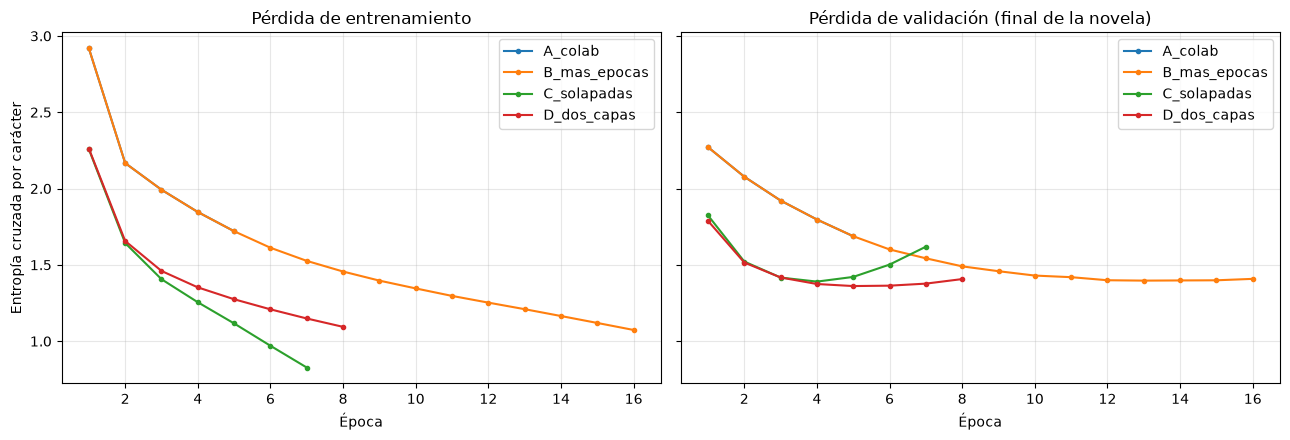

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for nombre, h in historias.items():
    linea, = ejes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker=".", label=nombre)
    ejes[0].plot(range(1, len(h["loss"]) + 1), h["loss"], marker=".", color=linea.get_color(), label=nombre)
ejes[0].set(title="Pérdida de entrenamiento", xlabel="Época", ylabel="Entropía cruzada por carácter")
ejes[1].set(title="Pérdida de validación (final de la novela)", xlabel="Época")
for eje in ejes:
    eje.grid(alpha=0.3); eje.legend()
plt.tight_layout(); plt.savefig(FIGURAS / "01_curvas_lm.png", dpi=120); plt.show()

**Lectura.** (Ver los valores en la tabla de arriba y el análisis en el `README.md`.) Lo que se busca en la figura:
si la pérdida de entrenamiento sigue bajando mientras la de validación sube, el modelo está memorizando el libro.
El *early stopping* se queda con los pesos de la mejor época de validación.

In [10]:
MEJOR = experimentos.loc[experimentos["perdida_val"].idxmin(), "experimento"]
print("Mejor modelo por pérdida de validación:", MEJOR)
cfg_mejor = EXPERIMENTOS[MEJOR]
modelo_mejor = modelos[MEJOR]

Mejor modelo por pérdida de validación: D_dos_capas


## 5. Generación

Como en el colab, copiamos los pesos a un **modelo paso a paso** que recibe un carácter y el estado de cada GRU
y devuelve la distribución del siguiente carácter y el estado nuevo. Así generar cuesta un paso por carácter en
lugar de releer todo el texto cada vez. La función acepta un lote de semillas (*prompts*) para generar varias
muestras a la vez.

In [11]:
def modelo_paso(modelo_entrenado, oculto, capas, embedding=256):
    entrada = keras.Input(shape=(1,), dtype="int32")
    estados = [keras.Input(shape=(oculto,)) for _ in range(capas)]
    x = layers.Embedding(TAM_VOCAB, embedding)(entrada)
    nuevos = []
    for i in range(capas):
        x, estado = layers.GRU(oculto, return_sequences=(i < capas - 1), return_state=True)(x, initial_state=estados[i])
        nuevos.append(estado)
    salida = layers.Dense(TAM_VOCAB, activation="softmax")(x)
    paso = keras.Model([entrada, *estados], [salida, *nuevos])
    paso.set_weights(modelo_entrenado.get_weights())
    return paso

caracter_a_id = {c: i for i, c in enumerate(vocabulario)}

def avanzar(paso, ids, estados):
    # Un paso del modelo; todo en numpy para no mezclar arrays y tensores entre llamadas.
    probs, *estados = paso([np.asarray(ids, "int32"), *estados], training=False)
    return np.asarray(probs), [np.asarray(e) for e in estados]

def generar(paso, semillas, largo=500, temperatura=None, oculto=1024, capas=1, rng=None):
    # temperatura=None es greedy (argmax), como en el colab; si no, se muestrea de p^(1/T) renormalizada.
    rng = rng or np.random.default_rng(SEMILLA)
    estados_por_semilla, ultimas = [], []
    for semilla in semillas:            # cada semilla tiene su largo, así que se "lee" una por una
        estados = [np.zeros((1, oculto), "float32") for _ in range(capas)]
        for c in semilla:
            probs, estados = avanzar(paso, [[caracter_a_id.get(c, 1)]], estados)
        estados_por_semilla.append(estados); ultimas.append(probs[0])
    estados = [np.concatenate([e[i] for e in estados_por_semilla]) for i in range(capas)]
    probs = np.stack(ultimas)
    generado = [[] for _ in semillas]
    for _ in range(largo):
        if temperatura is None:
            siguiente = probs.argmax(axis=-1)
        else:
            logits = np.log(probs + 1e-9) / temperatura
            p = np.exp(logits - logits.max(axis=-1, keepdims=True)); p /= p.sum(axis=-1, keepdims=True)
            siguiente = np.array([rng.choice(TAM_VOCAB, p=fila) for fila in p])
        for lista, i in zip(generado, siguiente):
            lista.append(vocabulario[i])
        probs, estados = avanzar(paso, siguiente[:, None], estados)
    return [s + "".join(g) for s, g in zip(semillas, generado)]

paso_mejor = modelo_paso(modelo_mejor, cfg_mejor["oculto"], cfg_mejor["capas"])

In [12]:
SEMILLAS = ["María", "Mi padre", "Aquella noche", "Efraín, ", "La madre de "]
for temperatura in (None, 0.5, 0.8):
    print("=" * 30, "greedy" if temperatura is None else f"temperatura {temperatura}", "=" * 30)
    for muestra in generar(paso_mejor, SEMILLAS[:2], largo=350, temperatura=temperatura,
                           oculto=cfg_mejor["oculto"], capas=cfg_mejor["capas"]):
        print(muestra, "\n")

============================== greedy ==============================
María estaba allá de la casa.
-¿Conque te ha dicho que se le había pasado esta noche en el corredor de la mano que me había pasado en el corredor de la mano que me había pasado en la mano y la mano de la mano que me había pasado en la mano y la mano de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la  

Mi padre se puso a mi padre.
-Sí, sí -le respondió con la mano para que se le había pasado en la mano y la mano de la mano que me había pasado en la mano y la mano de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la casa de la c 

============================== temperatura 0.5 ==============================
María y yo de comprender que la parte de mi madre, que ya no le perdiera yo que me entregó a mí.
-¿Y eso con el caballo no debe decir 

### 5.1 ¿Qué temperatura usar?

Leer muestras es subjetivo, así que medimos tres cosas sobre 10 muestras de 600 caracteres por temperatura
(las 5 semillas × 2):

- **Palabras válidas**: porcentaje de palabras generadas que existen en el libro. Mide si el modelo escribe
  español bien deletreado (más alto = mejor).
- **Distinct-2**: bigramas de palabras distintos / bigramas totales (Li et al., 2016). Mide diversidad; el
  *greedy* tiende a repetir frases en bucle (más alto = más diverso).
- **5-gramas copiados**: porcentaje de secuencias de 5 palabras generadas que aparecen tal cual en el libro. Mide
  memorización (muy alto = el modelo recita la novela en lugar de escribir texto nuevo).

In [13]:
palabras_libro = set(re.findall(r"\w+", texto.lower()))
tokens_libro = re.findall(r"\w+", texto.lower())
cincogramas_libro = set(zip(*(tokens_libro[i:] for i in range(5))))

def medir(muestras, semillas):
    validas = total = 0; bigramas = []; copiados = cinco = 0
    for muestra, semilla in zip(muestras, semillas):
        tokens = re.findall(r"\w+", muestra[len(semilla):].lower())[1:-1]   # sin las palabras cortadas en los bordes
        validas += sum(t in palabras_libro for t in tokens); total += len(tokens)
        bigramas += list(zip(tokens, tokens[1:]))
        gramas = list(zip(*(tokens[i:] for i in range(5))))
        copiados += sum(g in cincogramas_libro for g in gramas); cinco += len(gramas)
    return {"palabras_validas": 100 * validas / total, "distinct_2": 100 * len(set(bigramas)) / len(bigramas),
            "cincogramas_copiados": 100 * copiados / max(cinco, 1)}

semillas_eval = SEMILLAS * 2
filas, muestras_por_t = [], {}
for temperatura in (None, 0.2, 0.5, 0.8, 1.0, 1.2):
    muestras = generar(paso_mejor, semillas_eval, largo=600, temperatura=temperatura,
                       oculto=cfg_mejor["oculto"], capas=cfg_mejor["capas"], rng=np.random.default_rng(SEMILLA))
    etiqueta = "greedy" if temperatura is None else str(temperatura)
    muestras_por_t[etiqueta] = muestras
    filas.append({"temperatura": etiqueta, **medir(muestras, semillas_eval)})
generacion = pd.DataFrame(filas)
generacion.to_csv(RESULTADOS / "lm_temperatura.csv", index=False)
json.dump(muestras_por_t, open(RESULTADOS / "lm_muestras.json", "w"), ensure_ascii=False, indent=1)
generacion.round(1)

,temperatura,palabras_validas,distinct_2,cincogramas_copiados
0,greedy,100.0,4.0,0.8
1,0.2,99.9,34.4,2.8
2,0.5,97.3,62.8,0.5
3,0.8,90.7,86.2,0.3
4,1.0,81.3,91.8,0.0
5,1.2,72.4,94.5,0.0


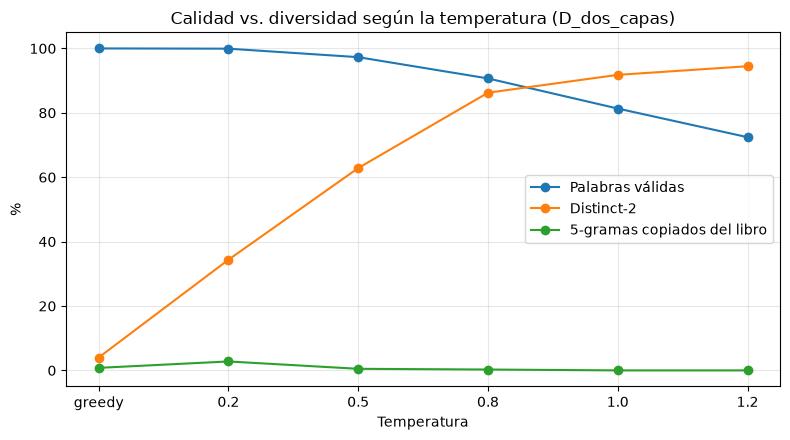

In [14]:
fig, eje = plt.subplots(figsize=(8, 4.5))
for columna, nombre in [("palabras_validas", "Palabras válidas"), ("distinct_2", "Distinct-2"),
                        ("cincogramas_copiados", "5-gramas copiados del libro")]:
    eje.plot(generacion["temperatura"], generacion[columna], marker="o", label=nombre)
eje.set(title=f"Calidad vs. diversidad según la temperatura ({MEJOR})", xlabel="Temperatura", ylabel="%")
eje.grid(alpha=0.3); eje.legend()
plt.tight_layout(); plt.savefig(FIGURAS / "02_temperatura.png", dpi=120); plt.show()

### 5.2 Comparación con el modelo del colab

Misma semilla y misma temperatura con el modelo A (el colab tal cual) y con el mejor modelo.

In [15]:
paso_colab = modelo_paso(modelos["A_colab"], 1024, 1)
for nombre, paso_m, cfg in [("A_colab", paso_colab, EXPERIMENTOS["A_colab"]), (MEJOR, paso_mejor, cfg_mejor)]:
    muestras = generar(paso_m, SEMILLAS, largo=600, temperatura=0.5, oculto=cfg["oculto"], capas=cfg["capas"],
                       rng=np.random.default_rng(SEMILLA))
    print(f"{nombre:<14}", {k: round(v, 1) for k, v in medir(muestras, SEMILLAS).items()})
    print("   ", muestras[0][:300].replace("\n", " "), "\n")

A_colab        {'palabras_validas': 82.6, 'distinct_2': 70.7, 'cincogramas_copiados': 0.3}
    María y su padre de la cabeza de la mano por la mamante de su compañado de decir llegado de los noches de un perrido a la mus perrecidos de la casa. -¿Corlo para que sabe de me piendo por que se pues de la concadra comprende a la más de ella me deje que se amberca de mi padre de su hablera yo te hab 

D_dos_capas    {'palabras_validas': 97.0, 'distinct_2': 76.9, 'cincogramas_copiados': 0.8}
    María y mi padre con la mujer de la mano y que tenía de la noche, porque en los labios de María entre los pasos el canto del río, y al recorrar su familia de su cariña para amarlarle el peñar de los combates, y la cabeza en este mozo para llegar a la casa de José y Emma y yo acariciaba la mañana del 



## 6. Muestra final

Texto de 1.000 caracteres con la temperatura elegida en el análisis de 5.1 (ver `README.md`).

In [17]:
TEMPERATURA_FINAL = 0.5
print(generar(paso_mejor, ["maria es una campesina colombia"], largo=1000, temperatura=TEMPERATURA_FINAL,
              oculto=cfg_mejor["oculto"], capas=cfg_mejor["capas"])[0])

maria es una campesina colombiada por la cintura que había entrado a la puerta de su padre que tenía a mi madre.
-Es que se le confiestro de que se puso a amar con el pañolón y sin que el desale de mi madre y yo por la mañana entre mi corazón de mi padre.
-¿Y eso desea que lo que hace con eso? ¿no es eso?
-Pues a mí con el puño con los perros con ellas y yo sonriendo y yo con las manos y manejas de la cabeza que había enternado ya y su fina de la mano y me mirar a María del sol y a María y mi padre olvidará con la mano que le había pesado en la parte que condición y mucho en el oratorio.
-¿Qué es lo que yo lo ha encargado?
-No hay para ver a su vida. Por esa primera vez de haber sido después de haber ser de su padre.
-Por sus miradas y estoy causar de su amante llamar a mi padre mucho. Es tan balanza y dispensable de que yo no te agradezco con el pañolón y la primera vez que me preparaba con los perros con las manos y las manos y yo. Me apresuró a decirte a ver a Emma que me llamaba.
-